# 06 - Retrieval model evaluation

Compares the four retrievers (TF-IDF, BM25, MiniLM, BGE) on the SciFact **dev** claims, plus a simple BM25+BGE hybrid as an extra.

Protocol (same as Laiba's notebooks): hyper-parameters were tuned on train, everything here is reported on dev. A document counts as relevant if it has annotated evidence (SUPPORT or CONTRADICT) for the claim. Claims with no evidence can't be scored for retrieval so they are left out.

Outputs go to `results/runs`, `results/metrics` and `results/`.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# this notebook lives in notebooks/, the package is one folder up
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

from retrieval.data import load_corpus, load_claims, build_qrels
from retrieval.search import get_retriever
from retrieval.evaluate import evaluate_run, save_run, save_metrics, per_query_first_hit_rank

RESULTS = ROOT / "results"
RESULTS.mkdir(exist_ok=True)

## 1. Load data

In [2]:
corpus = load_corpus()
doc_by_id = {d["id"]: d for d in corpus}

dev_claims = load_claims("dev")
qrels = build_qrels(dev_claims)          # {claim_id: {relevant doc ids}}
claim_text = {str(c["id"]): c["claim"] for c in dev_claims}
queries = {qid: claim_text[qid] for qid in qrels}

print("documents:", len(corpus))
print("dev claims:", len(dev_claims), "| scorable for retrieval:", len(queries))
print("avg relevant docs per claim:", round(np.mean([len(v) for v in qrels.values()]), 2))

documents: 5183
dev claims: 300 | scorable for retrieval: 188
avg relevant docs per claim: 1.11


## 2. Run every retriever on dev

Dense methods need the cached embeddings in `models/` (run `python scripts/build_embeddings.py` first) and `sentence-transformers` installed, because queries still have to be encoded.

In [3]:
METHODS = ["tfidf", "bm25", "minilm", "bge"]

runs, metrics = {}, {}
for m in METHODS:
    print("running", m)
    retriever = get_retriever(m)
    runs[m] = retriever.run(queries, k=100)
    metrics[m] = evaluate_run(runs[m], qrels)
    save_run(m, "dev", runs[m])
    save_metrics(m, "dev", metrics[m])

running tfidf
running bm25
running minilm


c:\Users\sabaj\AppData\Local\Programs\Python\Python314\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Loading weights: 100%|██████████| 103/103 [00:00<00:00, 4032.01it/s]


running bge


Loading weights: 100%|██████████| 199/199 [00:00<00:00, 2391.90it/s]


### Hybrid (extra)

Reciprocal rank fusion of BM25 and BGE. Only ranks are used, so the different score scales don't matter. `k=60` is the usual default.

In [4]:
def rrf(run_a, run_b, k=60, depth=100):
    fused = {}
    for qid in run_a:
        scores = {}
        for run in (run_a, run_b):
            for rank, doc in enumerate(run[qid][:depth], start=1):
                scores[doc] = scores.get(doc, 0) + 1 / (k + rank)
        fused[qid] = sorted(scores, key=scores.get, reverse=True)[:100]
    return fused

if "bm25" in runs and "bge" in runs:
    runs["hybrid"] = rrf(runs["bm25"], runs["bge"])
    metrics["hybrid"] = evaluate_run(runs["hybrid"], qrels)
    save_run("hybrid", "dev", runs["hybrid"])
    save_metrics("hybrid", "dev", metrics["hybrid"])

## 3. Results table

In [5]:
names = {
    "tfidf": "TF-IDF (tuned)",
    "bm25": "BM25 (tuned)",
    "minilm": "MiniLM (all-MiniLM-L6-v2)",
    "bge": "BGE (bge-small-en-v1.5)",
    "hybrid": "Hybrid BM25 + BGE (RRF)",
}
cols = ["Recall@1", "Recall@5", "Recall@10", "Recall@100", "MRR@10", "nDCG@10", "MAP"]

table = pd.DataFrame(metrics).T[cols].round(3)
table.index = [names[i] for i in table.index]
table = table.sort_values("nDCG@10", ascending=False)

table.to_csv(RESULTS / "retrieval_comparison_dev.csv")
display(table)

,Recall@1,Recall@5,Recall@10,Recall@100,MRR@10,nDCG@10,MAP
BGE (bge-small-en-v1.5),0.744,0.896,0.957,0.992,0.835,0.861,0.829
Hybrid BM25 + BGE (RRF),0.735,0.907,0.953,0.995,0.827,0.854,0.820
BM25 (tuned),0.696,0.857,0.924,0.959,0.785,0.815,0.779
MiniLM (all-MiniLM-L6-v2),0.613,0.863,0.912,0.989,0.731,0.773,0.730
TF-IDF (tuned),0.621,0.876,0.910,0.967,0.736,0.772,0.726


## 4. Plots

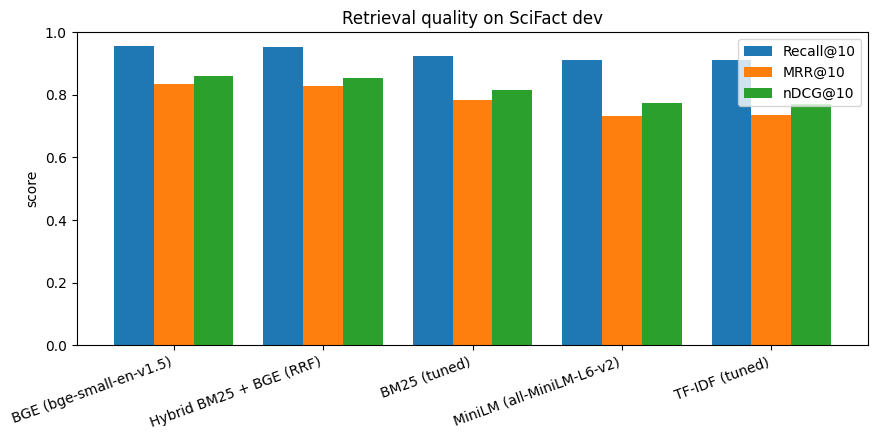

In [6]:
fig, ax = plt.subplots(figsize=(9, 4.5))
plot_cols = ["Recall@10", "MRR@10", "nDCG@10"]
table[plot_cols].plot(kind="bar", ax=ax, width=0.8)
ax.set_ylabel("score")
ax.set_ylim(0, 1)
ax.set_title("Retrieval quality on SciFact dev")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.savefig(RESULTS / "retrieval_bars.png", dpi=150)
plt.show()

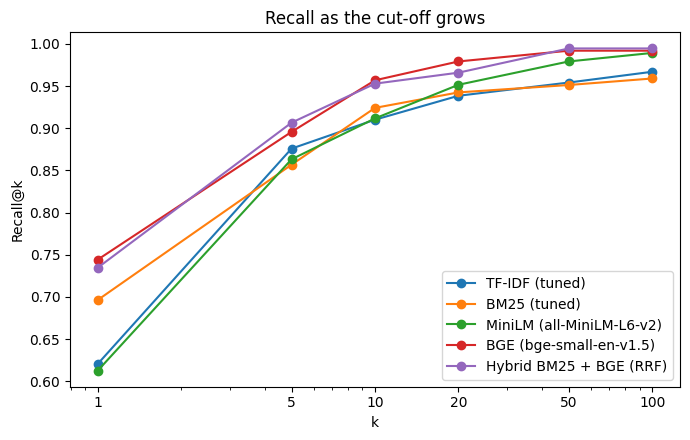

In [7]:
ks = [1, 5, 10, 20, 50, 100]
fig, ax = plt.subplots(figsize=(7, 4.5))
for key, label in names.items():
    if key in metrics:
        ax.plot(ks, [metrics[key][f"Recall@{k}"] for k in ks], marker="o", label=label)
ax.set_xscale("log")
ax.set_xticks(ks)
ax.set_xticklabels(ks)
ax.set_xlabel("k")
ax.set_ylabel("Recall@k")
ax.set_title("Recall as the cut-off grows")
ax.legend()
plt.tight_layout()
plt.savefig(RESULTS / "retrieval_recall_curve.png", dpi=150)
plt.show()

## 5. Is the difference real?

188 queries is not a lot, so a gap of a point or two in nDCG@10 can easily be noise. Paired bootstrap on the per-query nDCG@10: resample the queries with replacement, compute the mean difference each time, and look at the 95% interval.

In [8]:
def ndcg_per_query(run, qrels, k=10):
    out = {}
    for qid, rel in qrels.items():
        ranked = run[qid][:k]
        dcg = sum(1 / np.log2(i + 2) for i, d in enumerate(ranked) if d in rel)
        ideal = sum(1 / np.log2(i + 2) for i in range(min(len(rel), k)))
        out[qid] = dcg / ideal
    return pd.Series(out)

per_q = {m: ndcg_per_query(runs[m], qrels) for m in runs}

# sanity check against Laiba's evaluate_run
for m in runs:
    assert np.isclose(per_q[m].mean(), metrics[m]["nDCG@10"]), m


def paired_bootstrap(a, b, n_boot=10000, seed=42):
    rng = np.random.default_rng(seed)
    diff = (a - b).values
    idx = rng.integers(0, len(diff), size=(n_boot, len(diff)))
    boot_means = diff[idx].mean(axis=1)
    lo, hi = np.percentile(boot_means, [2.5, 97.5])
    p = min(1.0, 2 * min((boot_means <= 0).mean(), (boot_means >= 0).mean()))
    return diff.mean(), lo, hi, p

In [9]:
pairs = [("bm25", "tfidf"), ("minilm", "bm25"), ("bge", "bm25"), ("bge", "minilm")]
if "hybrid" in runs:
    pairs += [("hybrid", "bge"), ("hybrid", "bm25")]

pairs = [(a, b) for a, b in pairs if a in per_q and b in per_q]

rows = []
for a, b in pairs:
    diff, lo, hi, p = paired_bootstrap(per_q[a], per_q[b])
    rows.append({
        "A": names[a], "B": names[b],
        "mean diff (A-B)": round(diff, 3),
        "95% CI": f"[{lo:.3f}, {hi:.3f}]",
        "p": round(p, 4),
        "significant": not (lo <= 0 <= hi),
    })
display(pd.DataFrame(rows))

,A,B,mean diff (A-B),95% CI,p,significant
0,BM25 (tuned),TF-IDF (tuned),0.043,"[0.018, 0.069]",0.0006,True
1,MiniLM (all-MiniLM-L6-v2),BM25 (tuned),-0.042,"[-0.088, 0.003]",0.0658,False
2,BGE (bge-small-en-v1.5),BM25 (tuned),0.045,"[0.005, 0.087]",0.0270,True
3,BGE (bge-small-en-v1.5),MiniLM (all-MiniLM-L6-v2),0.087,"[0.055, 0.121]",0.0000,True
4,Hybrid BM25 + BGE (RRF),BGE (bge-small-en-v1.5),-0.007,"[-0.039, 0.023]",0.6708,False
5,Hybrid BM25 + BGE (RRF),BM25 (tuned),0.038,"[0.016, 0.060]",0.0006,True


## 6. Error analysis

Where does keyword search fail but embeddings succeed, and the other way round? Using BM25 vs BGE (change `A` and `B` below to compare something else).

In [10]:
A, B = "bm25", "bge"
first_a = per_query_first_hit_rank(runs[A], qrels)
first_b = per_query_first_hit_rank(runs[B], qrels)

def found_in_top10(rank):
    return rank is not None and rank <= 10

only_b = [q for q in qrels if found_in_top10(first_b[q]) and not found_in_top10(first_a[q])]
only_a = [q for q in qrels if found_in_top10(first_a[q]) and not found_in_top10(first_b[q])]
neither = [q for q in qrels if not found_in_top10(first_a[q]) and not found_in_top10(first_b[q])]

print(f"found only by {B}: {len(only_b)}")
print(f"found only by {A}: {len(only_a)}")
print(f"missed by both:    {len(neither)}")

found only by bge: 9
found only by bm25: 3
missed by both:    3


In [11]:
def show_cases(qids, n=5):
    for qid in qids[:n]:
        rel_id = sorted(qrels[qid])[0]
        print("claim   :", claim_text[qid])
        print("relevant:", doc_by_id[rel_id]["title"])
        print(f"rank {A}: {first_a[qid]} | rank {B}: {first_b[qid]}")
        print("-" * 80)

print(f"=== found only by {B} ===")
show_cases(only_b)
print(f"=== found only by {A} ===")
show_cases(only_a)
print("=== missed by both ===")
show_cases(neither)

=== found only by bge ===
claim   : Cellular aging closely links to an older appearance.
relevant: Perceived age as clinically useful biomarker of ageing: cohort study.
rank bm25: None | rank bge: 9
--------------------------------------------------------------------------------
claim   : Many proteins in human cells can be post-translationally modified at lysine residues via acetylation.
relevant: Protein Lysine Acetylated/Deacetylated Enzymes and the Metabolism-Related Diseases
rank bm25: 11 | rank bge: 3
--------------------------------------------------------------------------------
claim   : Obesity is determined solely by environmental factors.
relevant: Genetics of obesity in adult adoptees and their biological siblings.
rank bm25: 14 | rank bge: 2
--------------------------------------------------------------------------------
claim   : Ribosomopathies have a low degree of cell and tissue specific pathology.
relevant: Ribosome-Mediated Specificity in Hox mRNA Translation and Ve

## 7. Notes for the report

Fill these in after looking at the real numbers above (don't copy them from here, they depend on your run):

- Which method has the best nDCG@10 / Recall@10, and is the gap over BM25 significant?
- How much did tuning help TF-IDF, and did BM25 beat it?
- Do the dense models catch claims where the wording differs from the abstract (the "found only by" cases)? What kind of claims does BM25 win on (numbers, rare terms, names)?
- Does the hybrid help or not?
- Limits: only 188 dev claims, relevance means "has evidence" so other useful documents count as misses, and these numbers are not comparable to published BEIR scores because the query set is different.